In [1]:
import os
import sys
from pathlib import Path

# Add the project root (one level up from the notebooks folder) to the Python path
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

print(f"Added {project_root} to Python path.")

Added /Users/varan/Repositories/mnist-math to Python path.


In [2]:
# %% [markdown]
# # Analysis: Standard vs. Hybrid Operation Embeddings
#
# This notebook analyzes the performance of the ResNet-18 baseline models for the `mnist-math` task. We will compare the standard discrete `embedding` approach against the `hybrid` Fourier approach across four dimensions:
#
# 1. **Convergence & Sample Efficiency:** Which model learns faster?
# 2. **Generalization (OOD):** Can the models perform arithmetic on unseen operations?
# 3. **Error Typology:** When the models fail, do they fail on the sign (direction) or the magnitude (distance)?
# 4. **Latent Space Geometry:** How are the operations and context images structured in the latent space?

# %%
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from sklearn.manifold import TSNE

from data_pipeline import get_arithmetic_dataloader
from models import ResNet18LateFusion

# Set plotting style
sns.set_theme(style="whitegrid")
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

STANDARD_RUN_DIR = (
    Path(project_root) / "runs/baseline/20260418-162114-resnet-fourier-ops"
)
HYBRID_RUN_DIR = Path(project_root) / "runs/baseline/20260417-225956-resnet-hybrid-ops"

Using device: mps


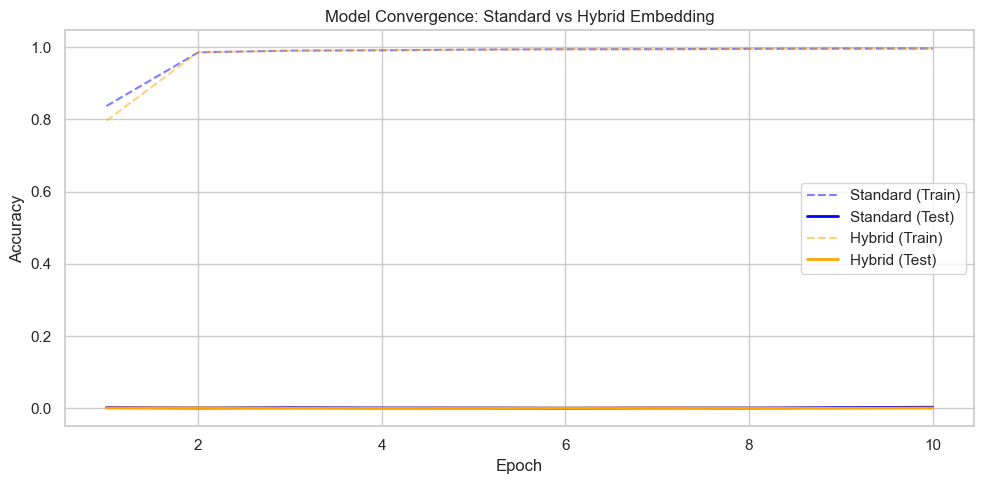

In [3]:
def load_history(run_dir: Path):
    with open(run_dir / "history.json") as f:
        return json.load(f)


std_hist = load_history(STANDARD_RUN_DIR)
hyb_hist = load_history(HYBRID_RUN_DIR)

epochs = [h["epoch"] for h in std_hist]
std_train_acc = [h["train"]["acc"] for h in std_hist]
std_test_acc = [h["test"]["acc"] for h in std_hist]

hyb_train_acc = [h["train"]["acc"] for h in hyb_hist]
hyb_test_acc = [h["test"]["acc"] for h in hyb_hist]

plt.figure(figsize=(10, 5))
plt.plot(epochs, std_train_acc, "--", color="blue", alpha=0.5, label="Standard (Train)")
plt.plot(epochs, std_test_acc, "-", color="blue", linewidth=2, label="Standard (Test)")
plt.plot(epochs, hyb_train_acc, "--", color="orange", alpha=0.5, label="Hybrid (Train)")
plt.plot(epochs, hyb_test_acc, "-", color="orange", linewidth=2, label="Hybrid (Test)")

plt.title("Model Convergence: Standard vs Hybrid Embedding")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
def load_model_from_run(run_dir: Path):
    with open(run_dir / "config.json") as f:
        config = json.load(f)

    # Extract configs
    ops = config["data"]["ops"]
    test_ops = config["data"].get("test_ops", ops)
    model_ops = (
        sorted(list(set(ops) | set(test_ops)))
        if config["model"]["op_embedding_type"] == "embedding"
        else ops
    )

    model = ResNet18LateFusion(
        ops=model_ops,
        num_classes=config["model"]["num_classes"],
        op_embed_dim=config["model"]["op_embed_dim"],
        mlp_hidden=config["model"]["mlp_hidden"],
        op_embedding_type=config["model"]["op_embedding_type"],
    ).to(device)

    ckpt = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    model.eval()

    return model, config


std_model, std_config = load_model_from_run(STANDARD_RUN_DIR)
hyb_model, hyb_config = load_model_from_run(HYBRID_RUN_DIR)

# IID Loader (Operations seen during training, e.g., [+1, +2, -1, -2])
iid_loader = get_arithmetic_dataloader(
    dataset_name="MNIST",
    batch_size=128,
    is_train=False,
    ops=std_config["data"]["ops"],
    num_workers=0,
)

# OOD Loader (Operations NEVER seen during training, e.g., [+3, -3])
ood_ops = [3, -3]  # Adjust based on your experiments
ood_loader = get_arithmetic_dataloader(
    dataset_name="MNIST", batch_size=128, is_train=False, ops=ood_ops, num_workers=0
)

In [5]:
def evaluate_loader(model, loader):
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in loader:
            img = batch["ctx_img"].to(device)
            op = batch["op"].to(device)
            tgt = batch["tgt_label"].to(device)

            logits = model(img, op)
            preds = logits.argmax(dim=1)
            correct += (preds == tgt).sum().item()
            total += tgt.size(0)
    return correct / total


print("--- Standard Embedding Model ---")
print(f"IID Accuracy: {evaluate_loader(std_model, iid_loader):.2%}")
print(f"OOD Accuracy: {evaluate_loader(std_model, ood_loader):.2%}")

print("\n--- Hybrid Embedding Model ---")
print(f"IID Accuracy: {evaluate_loader(hyb_model, iid_loader):.2%}")
print(f"OOD Accuracy: {evaluate_loader(hyb_model, ood_loader):.2%}")

--- Standard Embedding Model ---
IID Accuracy: 99.14%
OOD Accuracy: 0.24%

--- Hybrid Embedding Model ---
IID Accuracy: 98.20%
OOD Accuracy: 0.10%


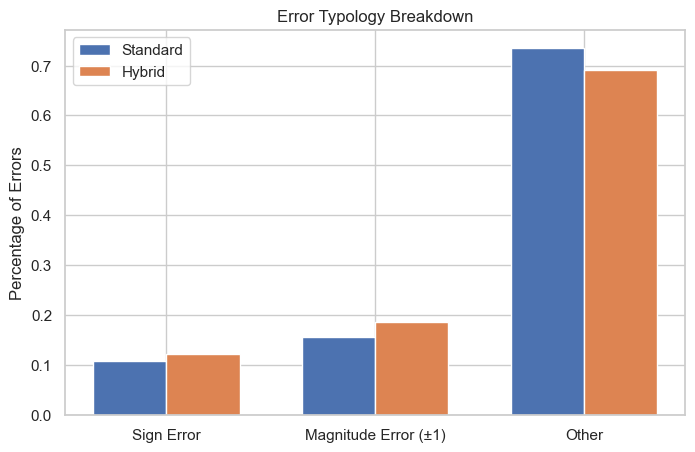

In [6]:
# Error Typology: Sign vs Magnitude
# When the model gets the math wrong, *how* is it failing? Did it add instead of subtract (Sign Error), or did it miscalculate the distance (Magnitude Error)?


def analyze_errors(model, loader):
    total_errors = 0
    sign_errors = 0
    mag_errors = 0
    other_errors = 0

    with torch.no_grad():
        for batch in loader:
            img = batch["ctx_img"].to(device)
            op = batch["op"].to(device)
            ctx_label = batch["ctx_label"].to(device)
            tgt_label = batch["tgt_label"].to(device)

            preds = model(img, op).argmax(dim=1)

            incorrect_mask = preds != tgt_label
            errors_ctx = ctx_label[incorrect_mask]
            errors_op = op[incorrect_mask]
            errors_pred = preds[incorrect_mask]

            total_errors += incorrect_mask.sum().item()

            for c, o, p in zip(errors_ctx, errors_op, errors_pred):
                c_val = c.item()
                o_val = int(o.item())
                p_val = p.item()

                # Sign Error: Applied opposite operation (-o instead of +o)
                if p_val == (c_val - o_val) % 10:
                    sign_errors += 1
                # Magnitude Error: Got the direction right, but step was off by 1
                elif (
                    p_val == (c_val + (o_val + 1)) % 10
                    or p_val == (c_val + (o_val - 1)) % 10
                ):
                    mag_errors += 1
                else:
                    other_errors += 1

    return {
        "total": total_errors,
        "sign_pct": sign_errors / max(1, total_errors),
        "mag_pct": mag_errors / max(1, total_errors),
        "other_pct": other_errors / max(1, total_errors),
    }


err_std = analyze_errors(std_model, iid_loader)
err_hyb = analyze_errors(hyb_model, iid_loader)

labels = ["Sign Error", "Magnitude Error (±1)", "Other"]
std_vals = [err_std["sign_pct"], err_std["mag_pct"], err_std["other_pct"]]
hyb_vals = [err_hyb["sign_pct"], err_hyb["mag_pct"], err_hyb["other_pct"]]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, std_vals, width, label="Standard")
ax.bar(x + width / 2, hyb_vals, width, label="Hybrid")

ax.set_ylabel("Percentage of Errors")
ax.set_title("Error Typology Breakdown")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()

"Other" Errors indicate that the model completely misunderstood the operation.

Extracting features and running t-SNE (this may take a minute)...


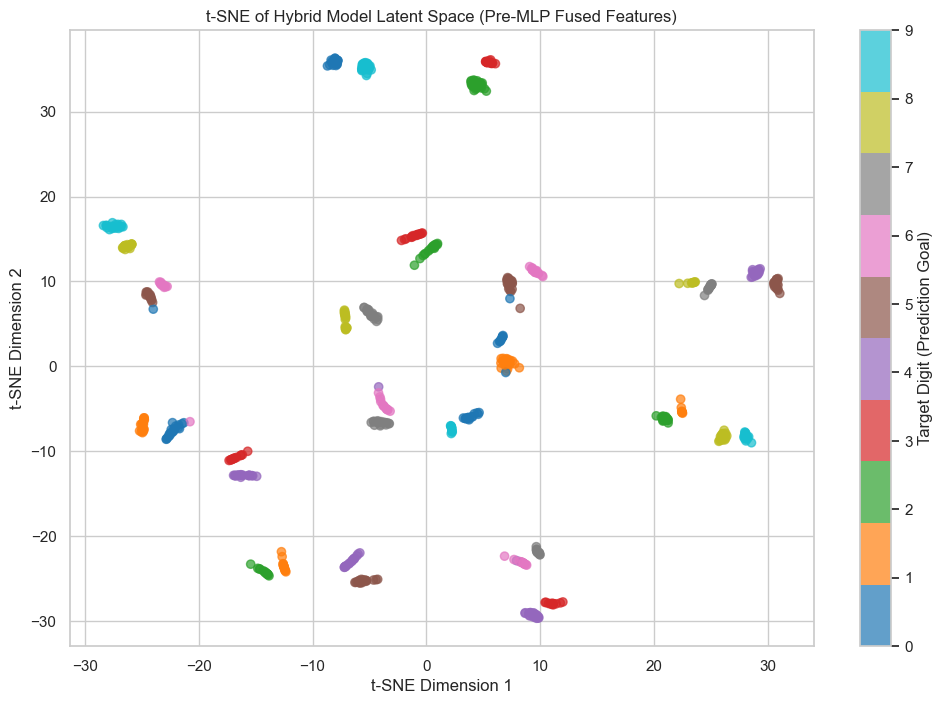

In [7]:
# Latent Space Visualization (t-SNE)
# Extract the features right after the image and operation embeddings are concatenated, just before they enter the final MLP. This shows us how the model organizes arithmetic logically.


def extract_features(model, loader, num_batches=5):
    features = []
    labels = []
    contexts = []
    ops_used = []

    # We will use a forward hook to grab the concatenated features
    # right before the head network starts
    hook_features = {}

    def hook(module, input, output):
        hook_features["in"] = input[0].detach().cpu()

    handle = model.head[0].register_forward_hook(hook)

    with torch.no_grad():
        for i, batch in enumerate(loader):
            if i >= num_batches:
                break
            img = batch["ctx_img"].to(device)
            op = batch["op"].to(device)

            _ = model(img, op)

            features.append(hook_features["in"])
            labels.append(batch["tgt_label"].cpu())
            contexts.append(batch["ctx_label"].cpu())
            ops_used.append(op.cpu())

    handle.remove()

    return (
        torch.cat(features),
        torch.cat(labels),
        torch.cat(contexts),
        torch.cat(ops_used),
    )


print("Extracting features and running t-SNE (this may take a minute)...")
hyb_feats, hyb_tgts, hyb_ctxs, hyb_ops = extract_features(hyb_model, iid_loader)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
feats_2d = tsne.fit_transform(hyb_feats.numpy())

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    feats_2d[:, 0], feats_2d[:, 1], c=hyb_tgts.numpy(), cmap="tab10", alpha=0.7
)
# scatter = plt.scatter(feats_2d[:, 0], feats_2d[:, 1], c=hyb_ops.numpy(), cmap='tab10', alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Target Digit (Prediction Goal)")

plt.title("t-SNE of Hybrid Model Latent Space (Pre-MLP Fused Features)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

# ### Analysis Space: Latent Space Geometry
# * Try modifying the scatter plot color mapping `c=hyb_ops.numpy()` to see if operations group locally within the larger target clusters.

Extracting features and running t-SNE (this may take a minute)...


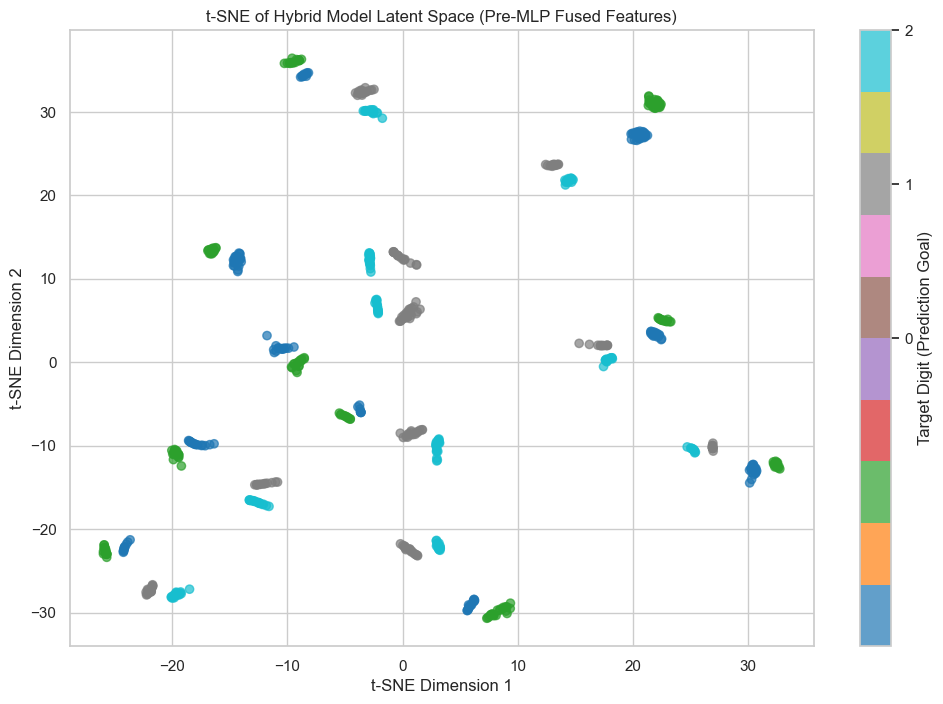

In [8]:
# Latent Space Visualization (t-SNE)
# Extract the features right after the image and operation embeddings are concatenated, just before they enter the final MLP. This shows us how the model organizes arithmetic logically.


def extract_features(model, loader, num_batches=5):
    features = []
    labels = []
    contexts = []
    ops_used = []

    # We will use a forward hook to grab the concatenated features
    # right before the head network starts
    hook_features = {}

    def hook(module, input, output):
        hook_features["in"] = input[0].detach().cpu()

    handle = model.head[0].register_forward_hook(hook)

    with torch.no_grad():
        for i, batch in enumerate(loader):
            if i >= num_batches:
                break
            img = batch["ctx_img"].to(device)
            op = batch["op"].to(device)

            _ = model(img, op)

            features.append(hook_features["in"])
            labels.append(batch["tgt_label"].cpu())
            contexts.append(batch["ctx_label"].cpu())
            ops_used.append(op.cpu())

    handle.remove()

    return (
        torch.cat(features),
        torch.cat(labels),
        torch.cat(contexts),
        torch.cat(ops_used),
    )


print("Extracting features and running t-SNE (this may take a minute)...")
hyb_feats, hyb_tgts, hyb_ctxs, hyb_ops = extract_features(hyb_model, iid_loader)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
feats_2d = tsne.fit_transform(hyb_feats.numpy())

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    feats_2d[:, 0], feats_2d[:, 1], c=hyb_ops.numpy(), cmap="tab10", alpha=0.7
)
plt.colorbar(scatter, ticks=range(10), label="Target Digit (Prediction Goal)")

plt.title("t-SNE of Hybrid Model Latent Space (Pre-MLP Fused Features)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()